## Customer Segmentation

This section groups customers into behavioral segments using selected Customer 360 financial, engagement, product, and service features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

file_path = Path("../data/final/customer_360.csv")
customer_360 = pd.read_csv(file_path)

print("Dataset shape:", customer_360.shape)
print("Customers:", customer_360["customer_id"].nunique())

Dataset shape: (5000, 29)
Customers: 5000


## Segmentation Features

We select behavioral and financial variables that can distinguish customers based on engagement, value, product usage, lending, and service activity.

In [2]:
segmentation_features = [
    "annual_income",
    "credit_score",
    "total_balance",
    "account_count",
    "total_transactions",
    "total_transaction_value",
    "products_number",
    "total_loan_amount",
    "loan_to_income_ratio",
    "total_service_interactions",
    "complaint_count",
    "recency_days"
]

segmentation_data = customer_360[segmentation_features].copy()

print("Segmentation data shape:", segmentation_data.shape)
print("\nMissing values:")
print(segmentation_data.isnull().sum())

print("\nFeature summary:")
display(segmentation_data.describe().T)

Segmentation data shape: (5000, 12)

Missing values:
annual_income                 0
credit_score                  0
total_balance                 0
account_count                 0
total_transactions            0
total_transaction_value       0
products_number               0
total_loan_amount             0
loan_to_income_ratio          0
total_service_interactions    0
complaint_count               0
recency_days                  0
dtype: int64

Feature summary:


,count,mean,std,min,25%,50%,75%,max
annual_income,"5,000.00","66,168.90","31,580.54","18,000.00","44,200.00","59,400.00","80,400.00","250,000.00"
credit_score,"5,000.00",652.54,80.02,354.00,597.00,653.00,707.00,850.00
total_balance,"5,000.00","85,935.03","115,899.48",0.00,"8,532.66","48,238.45","116,621.64","1,355,801.99"
account_count,"5,000.00",1.50,1.23,0.00,1.00,1.00,2.00,8.00
total_transactions,"5,000.00",15.48,9.20,0.00,12.00,18.00,22.00,36.00
total_transaction_value,"5,000.00","4,581.29","3,135.57",0.00,"2,685.39","4,911.20","6,592.68","22,745.51"
products_number,"5,000.00",2.00,1.41,0.00,1.00,2.00,3.00,9.00
total_loan_amount,"5,000.00","147,352.34","356,292.50",0.00,0.00,0.00,"104,560.43","3,322,170.32"
loan_to_income_ratio,"5,000.00",3.41,7.80,0.00,0.00,0.00,3.06,98.34
total_service_interactions,"5,000.00",1.56,1.51,0.00,0.00,1.00,3.00,9.00


## Feature Scaling

K-Means uses distance to form clusters. Since the selected features have very different numerical scales, standardization is applied so that each feature contributes more comparably to the clustering process.

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

segmentation_scaled = scaler.fit_transform(segmentation_data)

segmentation_scaled = pd.DataFrame(
    segmentation_scaled,
    columns=segmentation_features,
    index=customer_360.index
)

print("Scaled data shape:", segmentation_scaled.shape)

print("\nScaled feature means:")
print(segmentation_scaled.mean().round(2))

print("\nScaled feature standard deviations:")
print(segmentation_scaled.std().round(2))

Scaled data shape: (5000, 12)

Scaled feature means:
annual_income                 0.00
credit_score                 -0.00
total_balance                 0.00
account_count                 0.00
total_transactions           -0.00
total_transaction_value      -0.00
products_number              -0.00
total_loan_amount             0.00
loan_to_income_ratio          0.00
total_service_interactions   -0.00
complaint_count               0.00
recency_days                 -0.00
dtype: float64

Scaled feature standard deviations:
annual_income                1.00
credit_score                 1.00
total_balance                1.00
account_count                1.00
total_transactions           1.00
total_transaction_value      1.00
products_number              1.00
total_loan_amount            1.00
loan_to_income_ratio         1.00
total_service_interactions   1.00
complaint_count              1.00
recency_days                 1.00
dtype: float64


## Selecting the Number of Clusters

The Elbow Method and Silhouette Score are used to evaluate different numbers of customer segments before fitting the final K-Means model.

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(segmentation_scaled)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(segmentation_scaled, labels)
    )

cluster_evaluation = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertia_values,
    "silhouette_score": silhouette_values
})

display(cluster_evaluation.round(4))

,k,inertia,silhouette_score
0,2,"46,386.52",0.25
1,3,"39,879.87",0.27
2,4,"35,498.83",0.22
3,5,"32,067.33",0.21
4,6,"30,414.52",0.21
5,7,"28,985.72",0.20
6,8,"27,948.24",0.19


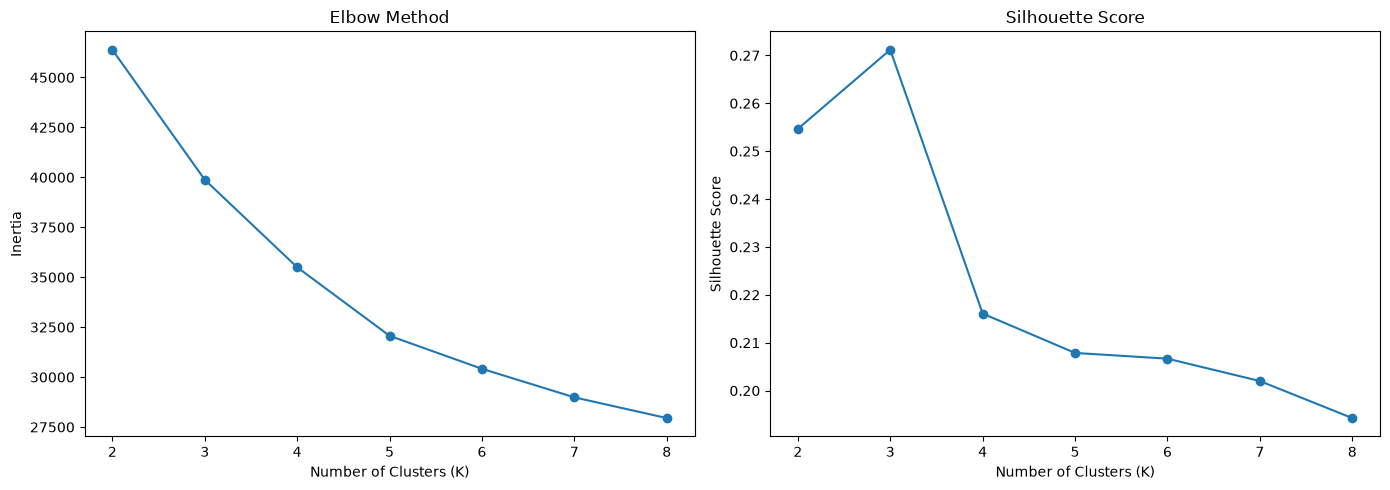

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    cluster_evaluation["k"],
    cluster_evaluation["inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(
    cluster_evaluation["k"],
    cluster_evaluation["silhouette_score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

## Final Customer Segmentation

A four-cluster K-Means model is fitted to create practical customer segments for business analysis.

In [6]:
# Fit final K-Means model
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

customer_360["segment"] = kmeans.fit_predict(segmentation_scaled)

print("Number of segments:", customer_360["segment"].nunique())
print("\nCustomer count by segment:")
print(
    customer_360["segment"]
    .value_counts()
    .sort_index()
)

Number of segments: 4

Customer count by segment:
segment
0    1128
1    2295
2    1167
3     410
Name: count, dtype: int64


## Segment Profiling

The average characteristics of each cluster are compared to understand the financial, engagement, product, loan, and service behavior of each customer segment.

In [7]:
segment_profile = (
    customer_360
    .groupby("segment")[segmentation_features]
    .mean()
    .round(2)
)

segment_profile

,annual_income,credit_score,total_balance,account_count,total_transactions,total_transaction_value,products_number,total_loan_amount,loan_to_income_ratio,total_service_interactions,complaint_count,recency_days
segment,,,,,,,,,,,,
0,"65,032.89",655.84,105.99,0.01,0.07,16.27,0.50,0.00,3.20,0.01,1.95,17.29
1,"67,067.71",649.83,"109,680.50",1.93,19.96,"5,884.10",2.29,"68,121.85",1.19,1.18,1.18,17.41
2,"66,526.05",654.71,"108,758.55",1.92,19.91,"5,942.22",2.33,"81,865.20",1.43,3.66,3.66,18.89
3,"63,246.59",652.46,"124,189.28",1.98,20.19,"5,974.47",3.56,"1,182,647.20",22.07,1.97,1.98,18.08


In [8]:
segment_profile_display = segment_profile.T

display(segment_profile_display)

segment,0,1,2,3
annual_income,"65,032.89","67,067.71","66,526.05","63,246.59"
credit_score,655.84,649.83,654.71,652.46
total_balance,105.99,"109,680.50","108,758.55","124,189.28"
account_count,0.01,1.93,1.92,1.98
total_transactions,0.07,19.96,19.91,20.19
total_transaction_value,16.27,"5,884.10","5,942.22","5,974.47"
products_number,0.50,2.29,2.33,3.56
total_loan_amount,0.00,"68,121.85","81,865.20","1,182,647.20"
loan_to_income_ratio,3.20,1.19,1.43,22.07
total_service_interactions,0.01,1.18,3.66,1.97


## Business Segment Names

The technical K-Means cluster numbers are converted into business-friendly customer segment names based on the behavioral and financial profiles identified above.

In [9]:
segment_names = {
    0: "Low Engagement Customers",
    1: "Core Banking Customers",
    2: "High-Service Customers",
    3: "High-Value Loan Customers"
}

customer_360["segment_name"] = customer_360["segment"].map(segment_names)

print("Segment distribution:")
print(
    customer_360["segment_name"]
    .value_counts()
)

Segment distribution:
segment_name
Core Banking Customers       2295
High-Service Customers       1167
Low Engagement Customers     1128
High-Value Loan Customers     410
Name: count, dtype: int64


In [10]:
segment_summary = (
    customer_360
    .groupby(["segment", "segment_name"])
    .agg(
        customer_count=("customer_id", "count"),
        avg_income=("annual_income", "mean"),
        avg_balance=("total_balance", "mean"),
        avg_transactions=("total_transactions", "mean"),
        avg_products=("products_number", "mean"),
        avg_loan_amount=("total_loan_amount", "mean"),
        avg_complaints=("complaint_count", "mean"),
        avg_recency=("recency_days", "mean")
    )
    .reset_index()
)

segment_summary.round(2)

,segment,segment_name,customer_count,avg_income,avg_balance,avg_transactions,avg_products,avg_loan_amount,avg_complaints,avg_recency
0,0,Low Engagement Customers,1128,"65,032.89",105.99,0.07,0.50,0.00,1.95,17.29
1,1,Core Banking Customers,2295,"67,067.71","109,680.50",19.96,2.29,"68,121.85",1.18,17.41
2,2,High-Service Customers,1167,"66,526.05","108,758.55",19.91,2.33,"81,865.20",3.66,18.89
3,3,High-Value Loan Customers,410,"63,246.59","124,189.28",20.19,3.56,"1,182,647.20",1.98,18.08


## Segment Distribution

The distribution shows the size of each customer segment and helps identify the largest and smallest customer groups.

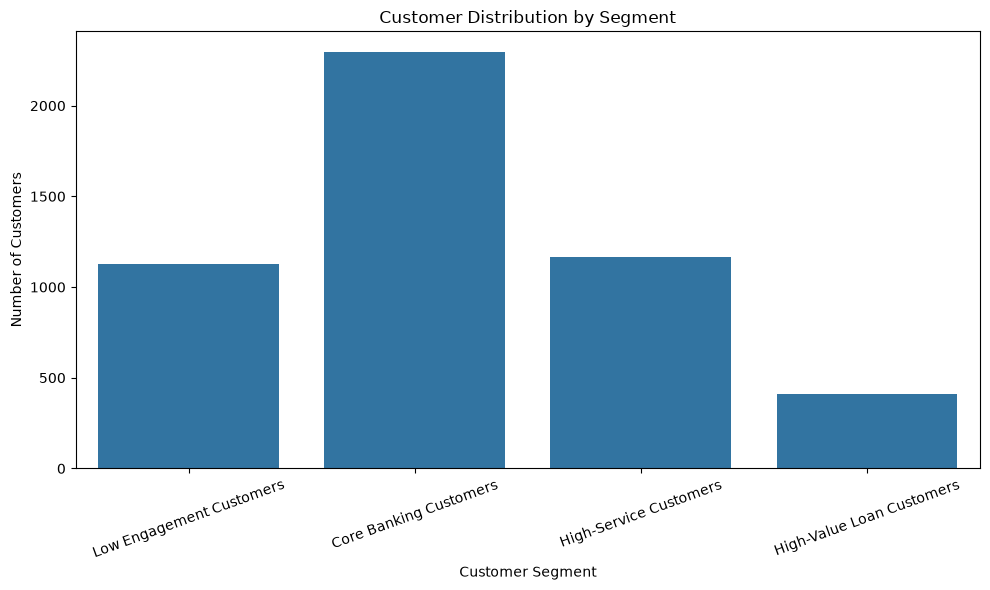

In [11]:
plt.figure(figsize=(10, 6))

segment_counts = (
    customer_360["segment_name"]
    .value_counts()
    .reindex(segment_names.values())
)

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Segment Behavioral Comparison

Key financial, engagement, product, and lending metrics are compared across the customer segments.

In [12]:
segment_comparison = (
    customer_360
    .groupby("segment_name")[
        [
            "total_balance",
            "total_transactions",
            "products_number",
            "total_loan_amount",
            "complaint_count",
            "recency_days"
        ]
    ]
    .mean()
)

segment_comparison

,total_balance,total_transactions,products_number,total_loan_amount,complaint_count,recency_days
segment_name,,,,,,
Core Banking Customers,"109,680.50",19.96,2.29,"68,121.85",1.18,17.41
High-Service Customers,"108,758.55",19.91,2.33,"81,865.20",3.66,18.89
High-Value Loan Customers,"124,189.28",20.19,3.56,"1,182,647.20",1.98,18.08
Low Engagement Customers,105.99,0.07,0.50,0.00,1.95,17.29


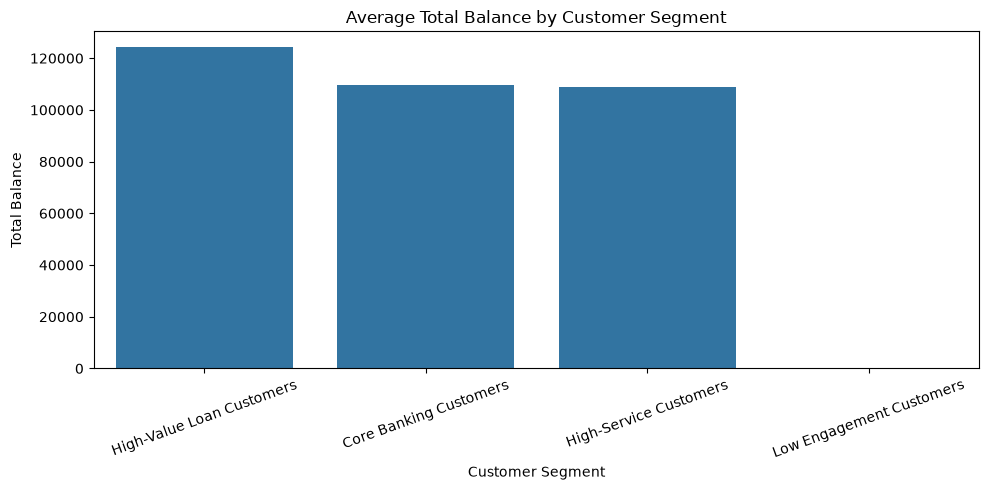

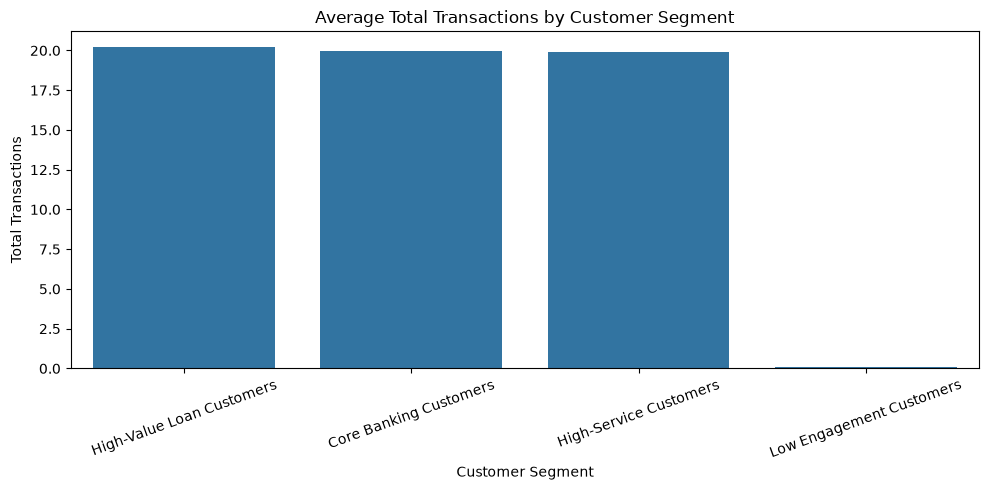

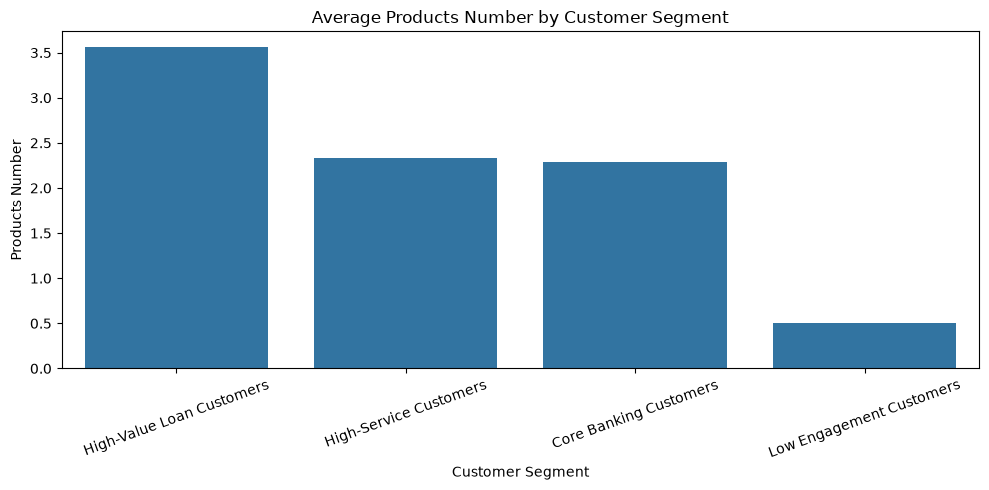

In [13]:
metrics = [
    "total_balance",
    "total_transactions",
    "products_number"
]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    values = segment_comparison[metric].sort_values(ascending=False)

    sns.barplot(
        x=values.index,
        y=values.values
    )

    plt.title(f"Average {metric.replace('_', ' ').title()} by Customer Segment")
    plt.xlabel("Customer Segment")
    plt.ylabel(metric.replace("_", " ").title())
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## Save Segmented Customer 360 Dataset

The final Customer 360 dataset, including the K-Means segment and business-friendly segment name, is saved for downstream dashboard and reporting work.

In [14]:
from pathlib import Path

output_path = Path("../data/final/customer_360_segmented.csv")

customer_360.to_csv(
    output_path,
    index=False
)

print("Saved successfully:", output_path)
print("Rows:", len(customer_360))
print("Columns:", len(customer_360.columns))
print("\nNew segmentation columns:")
print(["segment", "segment_name"])

Saved successfully: ..\data\final\customer_360_segmented.csv
Rows: 5000
Columns: 31

New segmentation columns:
['segment', 'segment_name']


In [15]:
print("Final validation")
print("-" * 40)

print("Rows:", customer_360.shape[0])
print("Columns:", customer_360.shape[1])
print("Unique customers:", customer_360["customer_id"].nunique())
print("Missing values:", customer_360.isnull().sum().sum())
print("Duplicate rows:", customer_360.duplicated().sum())
print("Unique segments:", customer_360["segment"].nunique())

print("\nSegment distribution:")
print(
    customer_360["segment_name"]
    .value_counts()
)

Final validation
----------------------------------------
Rows: 5000
Columns: 31
Unique customers: 5000
Missing values: 0
Duplicate rows: 0
Unique segments: 4

Segment distribution:
segment_name
Core Banking Customers       2295
High-Service Customers       1167
Low Engagement Customers     1128
High-Value Loan Customers     410
Name: count, dtype: int64
